# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [10]:
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
# include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

redSamples (generic function with 2 methods)

# Define Priors

In [3]:
NSamps = 8000;

priorTheta = Array{Any}(undef, 13);
priotY0 = Array{Any}(undef, 3);

priorTheta[1] = Normal(40.92, 10); priorTheta[2] = Normal(51.23, 10); priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

global sampsTh = zeros(NSamps, 13);
global sampsY0 = zeros(NSamps, 3);

Random.seed!(687865443); 

for i in 1:13
    sampsTh[:,i] = rand(priorTheta[i], NSamps);
end
for i in 1:3
    sampsY0[:,i] = rand(priotY0[i], NSamps);
end

sampsTh[:,2] .= 51.23; # T1 of Pyruvate is fixed since it is irrelevant for the model for the problem and can be estimated with experiments without cells. 
sampsTh[:,13] .= 15; # This will be re-writen with the empirical value once extracted from data

In [4]:
bounds = [zeros(12), zeros(12)];
boundY0 = [[0, 0, 0], [1600, 4e4, 1600]];
for i in 1:12
    if i >= 3
        if priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4) >= 0
            bounds[1][i] = priorTheta[i].untruncated.μ - (priorTheta[i].untruncated.σ*4);
        else
            bounds[1][i] = 0;
        end
        if priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4) <= 2
            bounds[2][i] = priorTheta[i].untruncated.μ + (priorTheta[i].untruncated.σ*4);
        else
            bounds[2][i] = 2;
        end
    elseif i == 1
        bounds[1][i] = priorTheta[i].μ - (priorTheta[i].σ*4);
        bounds[2][i] = priorTheta[i].μ + (priorTheta[i].σ*4);
    elseif i == 2
        bounds[1][i] = 51.23;
        bounds[2][i] = 51.23;
    end
end

In [9]:
priorInfer = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\Results\\PosteriorCompetitiveRepressionExp_Init_Try1.csv", DataFrame))


8000×16 Matrix{Float64}:
 41.1949  51.23  0.00772956  0.0186012  …  108.217   29811.1    503.579
 51.6101  51.23  0.00555101  0.0274524      92.1469  26464.8    606.874
 35.1197  51.23  0.00359025  0.022186       99.0307  24812.1   1052.16
 42.6028  51.23  0.00456304  0.0212256      85.5154  19561.7    687.445
 47.9692  51.23  0.00240846  0.0221916     728.696   19468.1     96.2662
 34.1855  51.23  0.00208756  0.0264356  …  966.98    13295.4     51.994
 41.3952  51.23  0.00365566  0.0360747     674.542   13456.3     34.8437
 43.0616  51.23  0.00375345  0.0534735     913.116   13598.4     19.7182
 40.0763  51.23  0.00456141  0.0192255     623.161    8511.54    89.1608
 38.109   51.23  0.00208587  0.0394897     793.988   24283.8     29.0393
  ⋮                                     ⋱                         ⋮
 49.7357  51.23  0.00225835  0.0386458      64.7826  17986.2    729.165
 30.5304  51.23  0.00610859  0.0242321     830.675   16655.5    477.217
 50.8069  51.23  0.00687396  0.02793   

# Random Experimental Design (Ran)

In [6]:
Nexp = 1;

Random.seed!(6532331);
PyrCons_All = round.(rand(Uniform(0,40), Nexp), digits = 1)
PyrCons = PyrCons_All[1]

18.0

In [11]:
global tsC2 = vcat(0, collect(15:5:395));
global ts = 0:tsC2[end];
global samps = convert.(Int, tsC2);

global sampsTh = priorInfer[:,1:13];
global sampsY0 = priorInfer[:,14:end];
CompRepUtil_Entro_OEDmc(PyrCons)

164.41130796489722

## Simulate Experiment Prio Prediction

In [9]:
simsPrior = Array{Any}(undef, 8000);

tsC2 = vcat(0, collect(15:5:395));
for i in 1:8000
    ts = 0:tsC2[end];
    ivss = [round(PyrCons[1], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(PyrCons[1], digits = 1)*1000, 0, round(PyrCons[1], digits = 1)*1000*(priorInfer[1,13]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);
    simsPrior[i] = SimulsAll;
end

In [10]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];
for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end

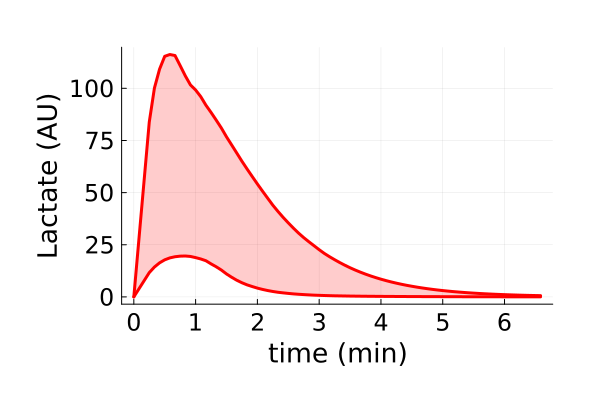

In [11]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "red", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "red", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="red", fillalpha=0.2)

# .................................................... PERFORM EXPERIMENT ....................................................

212.5 uL of pyruvate + 37.5 uL of media from the 40 mM solution 
<br>
175 uL of pyruvate + 75 uL of media from the 80 mM solution

# Extract Experimental Data 3.2 mM and 18 mM

In [12]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_3-2mMPyr_Dat.csv", mainpath*"3Mil_18-0mMPyr_Dat.csv"];
conce = [3.2, 18.0];

In [13]:
Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1])

Dict{String, Any} with 15 entries:
  "Means"  => [9177.49 46654.6; 6162.55 33020.3; … ; -6.00262 64.2728; 5.56735 …
  "stsl"   => [77 77]
  "obSta"  => [1 2]
  "sts"    => [0 0; 20 20; … ; 390 390; 395 395]
  "obser"  => 2
  "Y0us"   => [3200.0 18000.0; 0.0 0.0; … ; 0.0 0.0; 9177.49 46654.6]
  "ts"     => [1.0e-20 1.0e-20; 1.0 1.0; … ; 394.0 394.0; 395.0 395.0]
  "itp"    => [0.0, 0.0]
  "ScFms"  => [23.8997 21.5993]
  "ncells" => [4 4]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [821.947 12069.1; 491.932 8712.92; … ; 7.38584 24.0341; 6.8147 22…
  "m"      => 2
  "nts"    => [395 395]

# Simulate Experiment Prior Prediction

In [14]:
simsPrior = Array{Any}(undef, 8000);
sampsTh[:,13] .= dat["ScFms"][end];

tsC2 = dat["sts"];
for i in 1:8000
    tsC2 = dat["sts"][:,end];
    ts = 0:tsC2[end];
    ivss = [round(conce[end], digits = 1)*1000, 0, 0, priorInfer[i,14], priorInfer[i,15], priorInfer[i,16], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(priorInfer[i,1:13], 0), ivss, samps);

    simsPrior[i] = SimulsAll;
end

In [15]:
# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,1);
lacPirorSims = zeros(size(simsPrior[1])[1], 8000)
[lacPirorSims[:,i] = simsPrior[i][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:1
        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


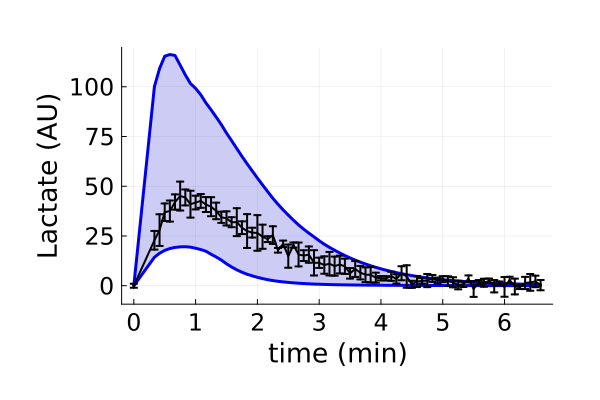

In [16]:
pr = plot(tsC2./60, PriorQuant[1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Lactate (AU)")
  plot!(tsC2./60, PriorQuant[2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PriorQuant[1], fillrange=PriorQuant[2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "")

# MLE to obtain a good first guess for inference

In [17]:
function ObjectFunctMECp_Multi_MLE(p)

    # Define parameter vectors for each amount of cells (last parameter is a time delay, not used in here)
    
    obj = 0;
    
    for i in 1:length(dat["stsl"])
        pD2 = vcat(p[1:end-3], dat["ScFms"][i], 0);

        # Define time vector
        t2cor = dat["sts"][:,i];

        # Define equaly-spaced time vector
        ts1 = collect(0:t2cor[end]);

        # Define initial value for simulation (use of experimental mean)
        ivss1 = [dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), 0, dat["Means"][1,i,2]/(dat["ScFms"][i]*0.12), p[end-2], p[end-1], p[end], 0, 0, 0, 0, 0, dat["Means"][1,i,1]/(dat["ScFms"][i]*0.12), dat["Means"][1,i,2], dat["Means"][1,i,1]];

        # Convert sampling vector to integer to extract correct elements from simulation
        samps1 = convert.(Int, t2cor);

        # Simulate
        SimOnTime1, SimOffTime1, SimAll1  = PyruvateHP_NMR_SolveAllCp(ts1, pD2, ivss1, samps1);
    
        # mm11 = sum((-1/2) .* (log(2*pi) .+ log.((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2) .+ (((SimOnTime1[:,14]/maximum(dat["Means"][:,i,1])) .- 
        #                 (dat["Means"][:,i,1]/maximum(dat["Means"][:,i,1]))).^2)./((dat["Erros"][:,i,1]/maximum(dat["Means"][:,i,1])).^2)));
        mm11 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,1].^2) .+ ((SimOnTime1[:,14] .- dat["Means"][:,i,1]).^2)./(dat["Erros"][:,i,1].^2)));
        mm22 = sum((-1/2) .* (log(2*pi) .+ log.(dat["Erros"][:,i,2].^2) .+ ((SimOnTime1[:,13] .- dat["Means"][:,i,2]).^2)./(dat["Erros"][:,i,2].^2)));
        # println(mm11)
        # obj = (mm21+mm22)*(mm11+mm12);
        if p[end-2] >= p[end-1]
            mm22 = mm22*10;
        end
        # obj = -(mm22)+obj;
        obj = -(mm22)+sqrt(abs(mm11))+obj;
    end
    
    return(obj)

end

ObjectFunctMECp_Multi_MLE (generic function with 1 method)

In [18]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE(p)

2376.906581346866

In [19]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:12], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*4, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.50 secs, 51 evals, 26 steps, improv/step: 0.385 (last = 0.3846), fitness=706.581352943
1.00 secs, 79 evals, 42 steps, improv/step: 0.405 (last = 0.4375), fitness=706.581352943
1.51 secs, 140 evals, 80 steps, improv/step: 0.412 (last = 0.4211), fitness=706.581352943
2.22 secs, 147 evals, 84 steps, improv/step: 0.417 (last = 0.5000), fitness=706.581352943
2.72 secs, 214 evals, 132 steps, improv/step: 0.424 (last = 0.4375), fitness=706.581352943
3.24 secs, 257 evals, 165 steps, improv/step: 0.370 (last = 0.1515), fitness=706.581352943
3.84 secs, 324 evals, 226 steps, improv/step: 0.407 (last = 0.5082), fitness=706.581352943
4.35 secs, 391 evals, 286 steps, improv/step: 0.395 (last = 0.3500), fitness=657.015050375
4.86 secs, 443 evals, 335 steps, improv/step: 0.370 (last = 0.2245), fitne

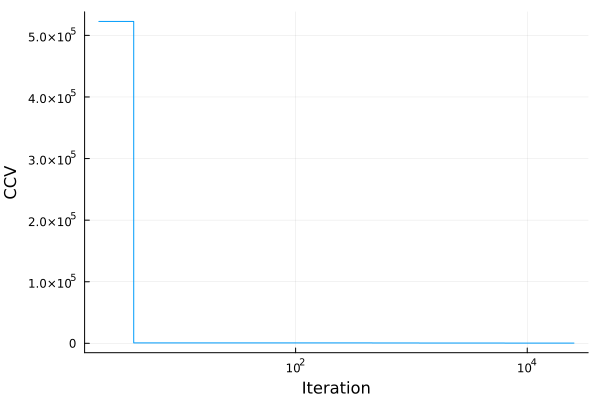

In [20]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

In [21]:
# Extract Parameter Vector
parfitT = zeros(15, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind]

15-element Vector{Float64}:
    44.02906241371164
    51.23
     0.005082244817127788
     0.021141407172193174
     0.04335293624984732
     0.0006577667001292022
     1.9088817521183312
     0.0026503285922934525
     1.995993960803319
     0.03655419283359881
     0.1918639221524964
     0.014495188169009082
    73.01235759716053
 25267.92399167775
  1030.3798599964266

In [22]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMTRRCmp_Exper_Ran1c.jld2", "FitsT",FitsT)
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_Ran1c.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

┌ Warning: Attempting to store var"#95#96".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [23]:
ppT = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED\\MLEResults\\resMVectTRRCmp_Exper_Ran1c.jld2")["resMMat"][:,1]


15-element Vector{Float64}:
    44.02906241371164
    51.23
     0.005082244817127788
     0.021141407172193174
     0.04335293624984732
     0.0006577667001292022
     1.9088817521183312
     0.0026503285922934525
     1.995993960803319
     0.03655419283359881
     0.1918639221524964
     0.014495188169009082
    73.01235759716053
 25267.92399167775
  1030.3798599964266

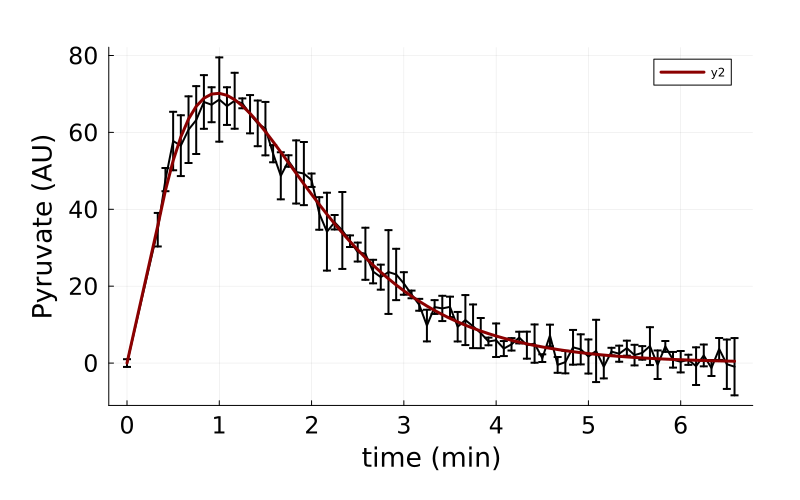

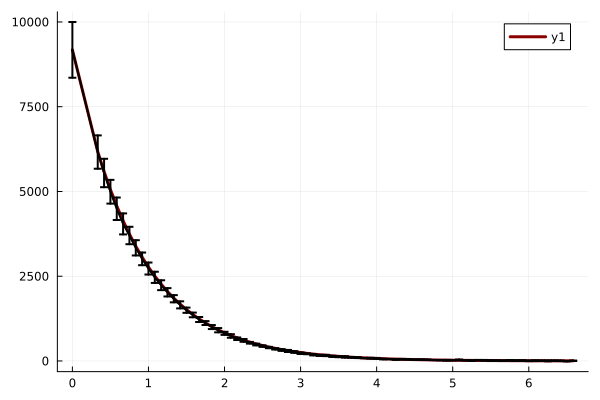

In [24]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,1];
ts = 0:tsC2[end];
ivss = [round(conce[1], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[1], digits = 1)*1000, 0, round(conce[1], digits = 1)*1000*(dat["ScFms"][1]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][1], 0), ivss, samps);

pps = plot(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)


ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

display(ps)

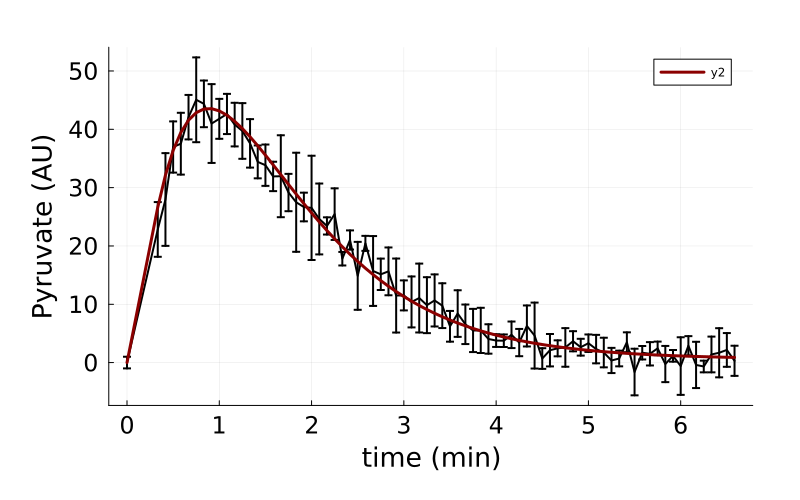

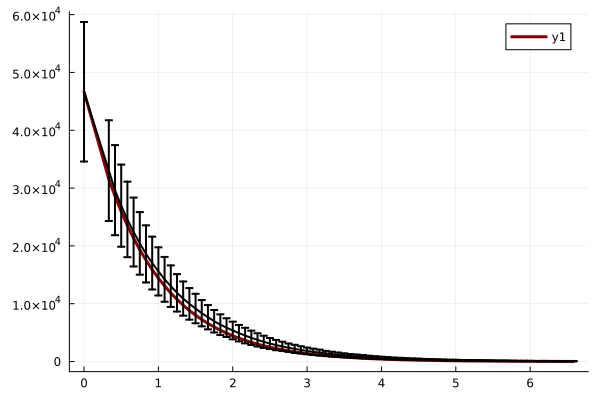

In [25]:
# Plot Simulation with best estimate against data
tsC2 = dat["sts"][:,end];
ts = 0:tsC2[end];
ivss = [round(conce[end], digits = 1)*1000, 0, 0, ppT[13], ppT[14], ppT[15], 0, 0, 0, 0, 0, round(conce[end], digits = 1)*1000, 0, round(conce[end], digits = 1)*1000*(dat["ScFms"][end]*0.12)];;
samps = convert.(Int, tsC2);

SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(ppT[1:12], dat["ScFms"][end], 0), ivss, samps);

pps = plot(dat["sts"][:,end]./60, dat["Means"][:,end,2], yerror = dat["Erros"][:,end,2], linewidth = 2, colour = "black", label = "",
            margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
            xlabel = "time (min)", ylabel = "Pyruvate (AU)", size = (800,500))

     plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4")
display(pps)

ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4")
plot!(dat["sts"][:,end]./60, dat["Means"][:,end,1], yerror = dat["Erros"][:,end,1], linewidth = 2, colour = "black", label = "")

display(ps)

## Compute structure for Stan's initial guess

In [26]:
preTrans = zeros(14);

preTrans[1] = (ppT[1]-40.92)/10; 
preTrans[2] = (ppT[3]-0.0055)/0.0055; 
preTrans[3] = (ppT[4]-0.0275)/0.0275;          
preTrans[4] = (ppT[5]-0.045)/0.045;
preTrans[5] = (ppT[6]-0.45)/0.45;
preTrans[6] = (ppT[7]-0.95)/0.95;
preTrans[7] = (ppT[8]-0.95)/0.95;
preTrans[8] = (ppT[9]-0.95)/0.95;
preTrans[9] = (ppT[10]-0.0085)/0.0085;
preTrans[10] = (ppT[11]-0.95)/0.95;
preTrans[11] = (ppT[12]-0.0029)/0.0029;


preTrans[12] = (ppT[13]-650)/260;
preTrans[13] = (ppT[14]-16000)/6400;
preTrans[14] = (ppT[15]-550)/275;

In [27]:

samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict(samps, names, 4)

4-element Vector{Dict{String, Any}}:
 Dict("kbnE" => 3.300493274541036, "LDH" => 1.7468358545324605, "kin" => -0.07595548779494761, "ki" => -0.7980379766815827, "kunE" => 1.1010462745298095, "kpl" => -0.2312215573747937, "NADH" => -2.219183240010921, "kup" => -0.9972101804291649, "T1_X" => 0.31090624137116407, "kbp" => 1.0093492127561383…)
 Dict("kbnE" => 3.300493274541036, "LDH" => 1.7468358545324605, "kin" => -0.07595548779494761, "ki" => -0.7980379766815827, "kunE" => 1.1010462745298095, "kpl" => -0.2312215573747937, "NADH" => -2.219183240010921, "kup" => -0.9972101804291649, "T1_X" => 0.31090624137116407, "kbp" => 1.0093492127561383…)
 Dict("kbnE" => 3.300493274541036, "LDH" => 1.7468358545324605, "kin" => -0.07595548779494761, "ki" => -0.7980379766815827, "kunE" => 1.1010462745298095, "kpl" => -0.2312215573747937, "NADH" => -2.219183240010921, "kup" => -0.9972101804291649, "T1_X" => 0.31090624137116407, "kbp" => 1.0093492127561383…)
 Dict("kbnE" => 3.300493274541036, "LDH" => 1.74

In [28]:
ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 3.30049
  "LDH"  => 1.74684
  "kin"  => -0.0759555
  "ki"   => -0.798038
  "kunE" => 1.10105
  "kpl"  => -0.231222
  "NADH" => -2.21918
  "kup"  => -0.99721
  "T1_X" => 0.310906
  "kbp"  => 1.00935
  "kr"   => 3.99834
  "NAD"  => 1.44811
  "kun"  => -0.998538
  "kbn"  => -0.0366014

# Inference

In [35]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_Ran1c_Try1c", model=Model, nchains =16,
            num_samples  = 500, num_warmup = 500, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [33]:
8000/16

500.0

In [ ]:
# modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\HP_PyrLac_CompetitiveRepressionModel_ExperimentalInit2.stan";

In [36]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Inference for Stan model: PyrCompRepr_Ran1c_Try1c_model
16 chains: each with iter=(500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500); warmup=(500,500,500,500,500,500,500,500,500,500,500,500,500,500,500,500); thin=(1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1); 16000 iterations saved.

Warmup took (127356, 129078, 133189, 121384, 124759, 135762, 127719, 137988, 130209, 136031, 125075, 130512, 121281, 128382, 129602, 127744) seconds, 574 hours total
Sampling took (107074, 120785, 108844, 98259, 104283, 95740, 103281, 114758, 99756, 98422, 107032, 83560, 108916, 95299, 103229, 121303) seconds, 464 hours total

                    Mean     MCSE   StdDev        5%       50%       95%    N_Eff  N_Eff/s    R_hat

lp__            -3.8e+02  6.0e-02  3.0e+00  -3.9e+02  -3.8e+02  -3.8e+02  2.5e+03  1.5e-03  1.0e+00
accept_stat__    9.4e-01  6.2e-03  1.2e-01   7.0e-01   9.8e-01   1.0e+00  3.4e+02  2.1e-04      1.0
stepsize__       6.3e-03  3.9e-04  2.1e-03   3.2e-03   6.1e-03   9.9e-03  3.0e+01 

(0, [-396.527 0.624509 … 25667.9 996.106; -396.527 0.0 … 25667.9 996.106; … ; -380.495 0.998454 … 18440.8 977.851; -380.51 0.999966 … 18318.4 844.115;;; -394.991 0.99367 … 10908.5 470.013; -394.991 0.0 … 10908.5 470.013; … ; -383.79 0.999911 … 29829.4 670.548; -384.321 0.994761 … 9865.64 483.789;;; -404.498 0.0999718 … 25156.2 1023.95; -404.498 0.0 … 25156.2 1023.95; … ; -381.266 0.999872 … 14399.3 266.257; -381.011 0.979495 … 24441.3 544.964;;; … ;;; -399.957 0.989277 … 27107.9 976.305; -399.957 0.0 … 27107.9 976.305; … ; -378.644 0.824061 … 13452.6 574.167; -378.353 0.998377 … 14839.5 780.322;;; -400.664 0.970268 … 16688.8 174.077; -400.664 0.0 … 16688.8 174.077; … ; -379.179 0.989034 … 20071.3 495.054; -380.609 0.99876 … 22322.2 452.421;;; -404.646 7.78014e-10 … 25267.9 1030.38; -404.646 2.3606e-9 … 25267.9 1030.38; … ; -381.602 0.997911 … 17618.7 746.767; -383.867 0.952594 … 15985.1 570.246], ["lp__", "accept_stat__", "stepsize__", "treedepth__", "n_leapfrog__", "divergent__", "ene

In [40]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PyrCompetitiveRepressionInferExp_Ran1c_Try1c.jld", "rc", rc, "chns", chns, "cnames", cnames)

In [47]:
poster = vcat(chns[501:end, end-15:end, 1], chns[501:end, end-15:end, 2], chns[501:end, end-15:end, 3], chns[501:end, end-15:end, 4], chns[501:end, end-15:end, 5], 
              chns[501:end, end-15:end, 6], chns[501:end, end-15:end, 7], chns[501:end, end-15:end, 8], chns[501:end, end-15:end, 9], chns[501:end, end-15:end, 10],
              chns[501:end, end-15:end, 11], chns[501:end, end-15:end, 12], chns[501:end, end-15:end, 13], chns[501:end, end-15:end, 14], chns[501:end, end-15:end, 15],
              chns[501:end, end-15:end, 16])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Ran1c_Try1c.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Ran1c_Try1c.csv", DataFrame(poster, :auto))

"D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Ran1c_Try1c.csv"

In [48]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED\\Results\\PosteriorCompetitiveRepressionExp_Ran1c_Try1c.csv", DataFrame))

8000×16 Matrix{Float64}:
 45.4193  51.23  0.00531007  …  21.5993  309.393   16462.9  530.589
 44.6276  51.23  0.00488229     21.5993  324.251   17733.8  477.127
 44.9207  51.23  0.0047382      21.5993  507.09    21009.7  286.057
 44.9691  51.23  0.00706172     21.5993  469.002   24331.7  209.49
 39.9374  51.23  0.00960695     21.5993  577.186   15990.2  941.68
 43.9337  51.23  0.00784408  …  21.5993  343.001   19231.1  785.299
 43.9112  51.23  0.00603164     21.5993  448.593   19291.4  601.287
 44.9227  51.23  0.00652211     21.5993   90.0327  16167.4  543.247
 44.9566  51.23  0.0117612      21.5993   78.0735  14528.5  810.493
 41.1356  51.23  0.00504637     21.5993   96.313   15338.0  486.563
  ⋮                          ⋱                                ⋮
 48.067   51.23  0.00541138     21.5993   84.9245  13724.4  740.496
 46.4106  51.23  0.00702417     21.5993  159.314   16598.2  677.671
 43.5984  51.23  0.00399282     21.5993  786.371   16096.2  143.311
 44.7983  51.23  0.0149961   

# Plot Posterior VS Prior

In [49]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

In [50]:
priorTheta[3] = Truncated(Normal(0.0055, 0.0055), 0,2); priorTheta[4] = Truncated(Normal(0.0275, 0.0275), 0,2); 
priorTheta[5] = Truncated(Normal(0.045, 0.045), 0,2); priorTheta[6] = Truncated(Normal(0.45, 0.45), 0,2); priorTheta[7] = Truncated(Normal(0.95, 0.95), 0,2); 
priorTheta[8] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[9] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[10] = Truncated(Normal(0.0085, 0.0085), 0,2);
priorTheta[11] = Truncated(Normal(0.95, 0.95), 0,2); priorTheta[12] = Truncated(Normal(0.0029, 0.0029), 0,2); priorTheta[13] = Normal(18.5, 2.29);

priotY0[1] = Truncated(Normal(650, 260), 0, 1600); priotY0[2] = Truncated(Normal(16000, 6400), 0, 4e4); priotY0[3] = Truncated(Normal(550, 275), 0, 1600);

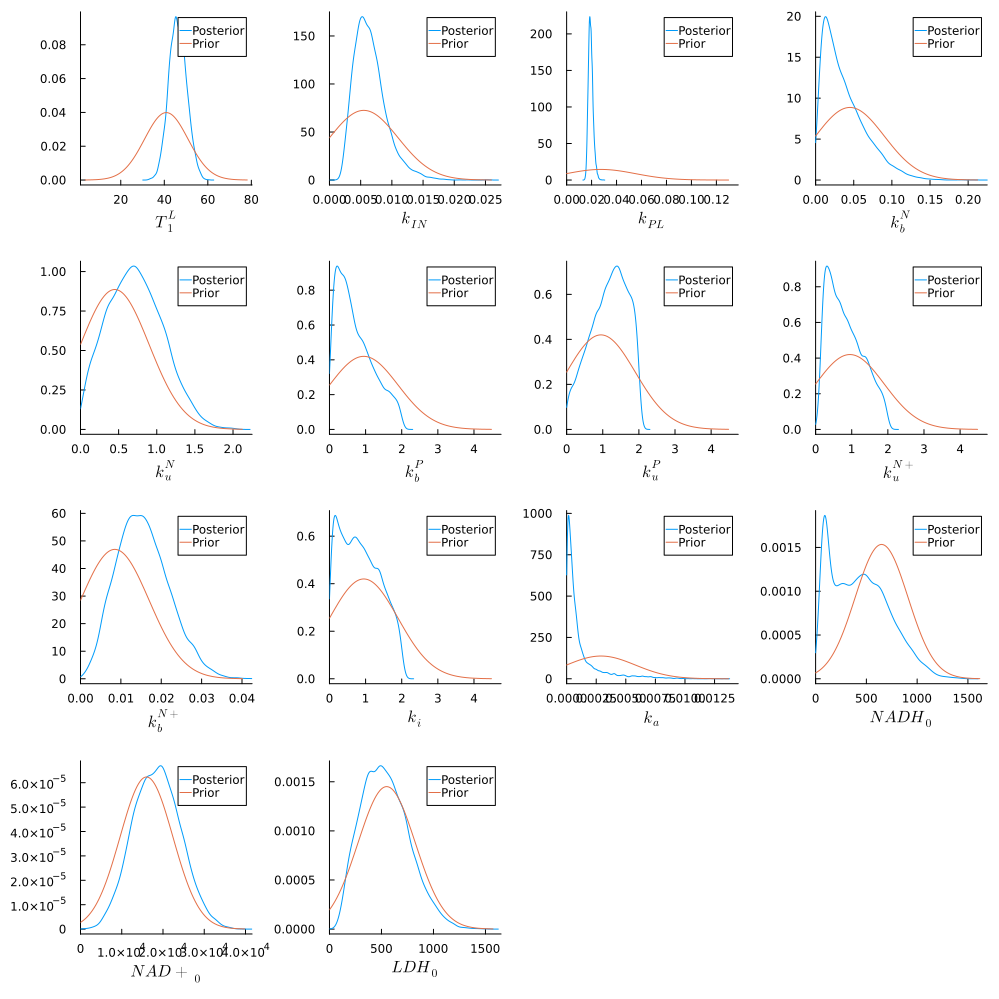

In [51]:
pp0 = plot(kde(poster[:,1]), label = "Posterior", xlabel = namess[1])
plot!(Normal(40.92, 10), label = "Prior")

pp1 = plot(kde(poster[:,3]), label = "Posterior", xlabel = namess[2])
plot!(Normal(0.0055, 0.0055), label = "Prior", xlim = (0, 0.0055+4*0.0055))

pp2 = plot(kde(poster[:,4]), label = "Posterior", xlabel = namess[3])
plot!(Normal(0.0275, 0.0275), label = "Prior", xlim = (0, 0.0275+4*0.0275))

pp3 = plot(kde(poster[:,5]), label = "Posterior", xlabel = namess[4])
plot!(Normal(0.045, 0.045), label = "Prior", xlim = (0, 0.045+4*0.045))

pp4 = plot(kde(poster[:,6]), label = "Posterior", xlabel = namess[5])
plot!(Normal(0.45, 0.45), label = "Prior", xlim = (0, 0.45+4*0.45))

pp5 = plot(kde(poster[:,7]), label = "Posterior", xlabel = namess[6])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp6 = plot(kde(poster[:,8]), label = "Posterior", xlabel = namess[7])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp7 = plot(kde(poster[:,9]), label = "Posterior", xlabel = namess[8])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp8 = plot(kde(poster[:,10]), label = "Posterior", xlabel = namess[9])
plot!(Normal(0.0085, 0.0085), label = "Prior", xlim = (0, 0.0085+4*0.0085))

pp9 = plot(kde(poster[:,11]), label = "Posterior", xlabel = namess[10])
plot!(Normal(0.95, 0.95), label = "Prior", xlim = (0, 0.95+4*0.95))

pp10 = plot(kde(poster[:,12]), label = "Posterior", xlabel = namess[11])
plot!(Normal(0.0029, 0.0029), label = "Prior", xlim = (0, 0.0029+4*0.0029))


pp11 = plot(kde(poster[:,14]), label = "Posterior", xlabel = namess[12])
plot!(Normal(650, 260), label = "Prior", xlim = (0, 650+4*260))

pp12 = plot(kde(poster[:,15]), label = "Posterior", xlabel = namess[13])
plot!(Normal(16000, 6400), label = "Prior", xlim = (0, 16000+4*6400))

pp13 = plot(kde(poster[:,16]), label = "Posterior", xlabel = namess[14])
plot!(Normal(550, 275), label = "Prior", xlim = (0, 550+4*275))

plot(pp0,pp1,pp2,pp3,pp4,pp5,pp6,pp7,pp8,pp9,pp10,pp11,pp12,pp13, size=(1000,1000), grid = false)

In [52]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,14:end]))))

24.938620357491413

In [47]:
using CairoMakie
using PairPlots
using DataFrames

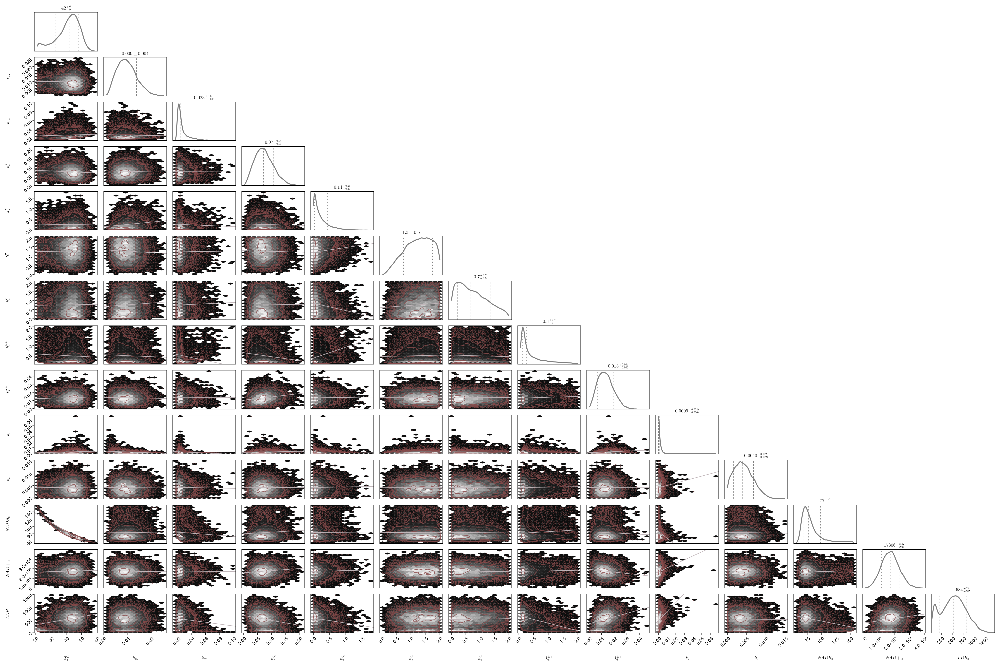

In [48]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,14:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_Ran1Experiment.svg", fig)


fig

# Simulate Experiment Current Posterior

In [49]:
simsPoster = Array{Any}(undef, 8000, 2);

for j in 1:2
for i in 1:8000
    tsC2 = dat["sts"][:,j];
    ts = 0:tsC2[end];
    ivss = [dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, 0, poster[i,14], poster[i,15], poster[i,16], 0, 0, 0, 0, 0, dat["Means"][1,j,1]/(dat["ScFms"][j]*0.12), 0, dat["Means"][1,j,1]];;
    samps = convert.(Int, tsC2);

    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp(ts, vcat(poster[i,1:12], dat["ScFms"][j], 0), ivss, samps);

    simsPoster[i,j] = SimulsAll;
end
end

### Experiment 1

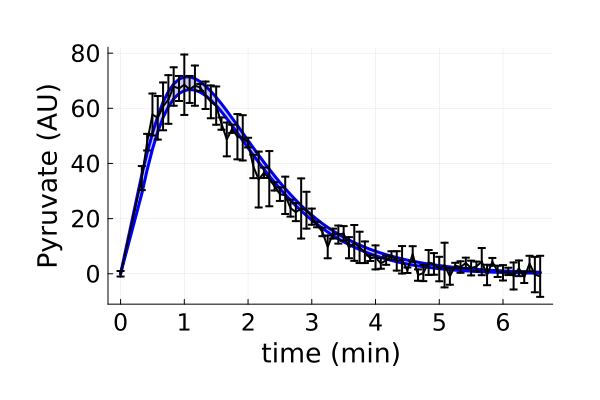

In [50]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,1][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,2], yerror = dat["Erros"][:,1,2], linewidth = 2, colour = "black", label = "")

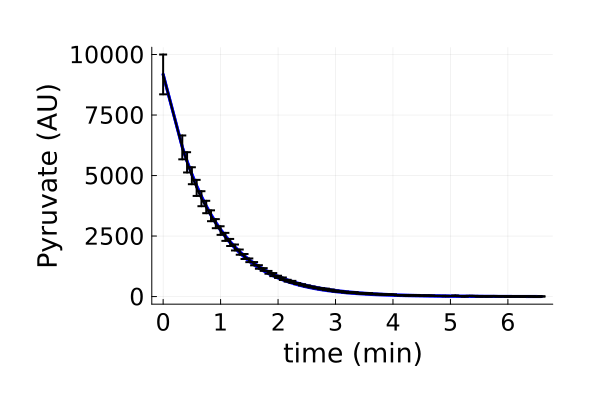

In [51]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,1][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,1], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,1], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,1], fillrange=PostQuant[2,1,1], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,1]./60, dat["Means"][:,1,1], yerror = dat["Erros"][:,1,1], linewidth = 2, colour = "black", label = "")

## Experiment 2

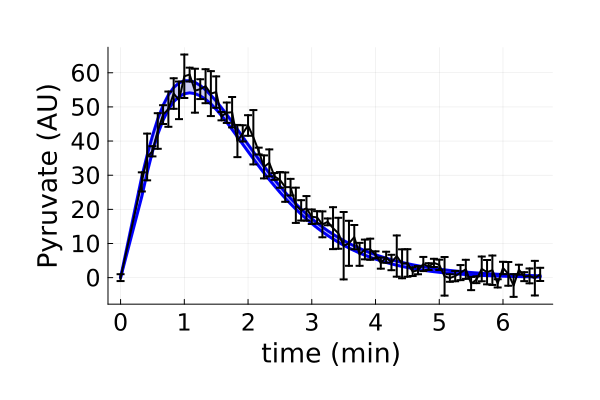

In [52]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
lacPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[lacPostSims[:,i] = simsPoster[i,2][:,13,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(lacPostSims[j,:], 99.5) for j in 1:size(lacPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(lacPostSims[j,:], 0.5 ) for j in 1:size(lacPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,2], yerror = dat["Erros"][:,2,2], linewidth = 2, colour = "black", label = "")

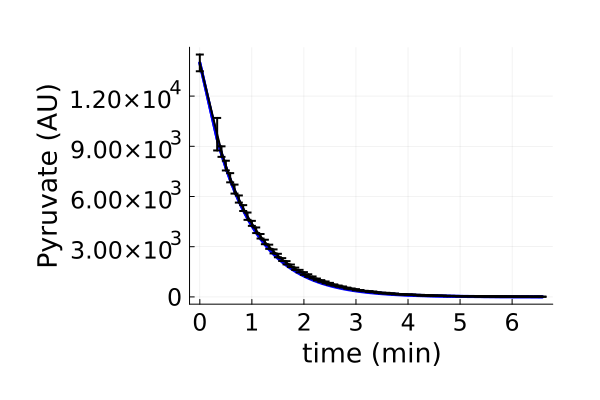

In [53]:
# Dims = Up/Down, Observable, Experiment
PostQuant = Array{Any}(undef,2,1,2);
pyrPostSims = zeros(size(simsPoster[1,1])[1], 8000)
[pyrPostSims[:,i] = simsPoster[i,2][:,14,1] for i in 1:8000 ];

for k in 1:1
    for m in 1:2
        PostQuant[1,k,m] = [percentile(pyrPostSims[j,:], 99.5) for j in 1:size(pyrPostSims)[1]]; # Up
        PostQuant[2,k,m] = [percentile(pyrPostSims[j,:], 0.5 ) for j in 1:size(pyrPostSims)[1]]; # Down
    end
end

pr = plot(tsC2./60, PostQuant[1,1,2], label = "", color = "blue", linewidth = 3,
    margin=10Plots.mm,xtickfont=font(16), ytickfont=font(16), guidefont=font(18), titlefont=font(18),
    xlabel = "time (min)", ylabel = "Pyruvate (AU)")
  plot!(tsC2./60, PostQuant[2,1,2], label = "", color = "blue", linewidth = 3)
  plot!(tsC2./60, PostQuant[1,1,2], fillrange=PostQuant[2,1,2], label="", color="blue3", fillalpha=0.2)

  plot!(dat["sts"][:,2]./60, dat["Means"][:,2,1], yerror = dat["Erros"][:,2,1], linewidth = 2, colour = "black", label = "")